# Residuals for Cox regression model: multiple myeloma

After fitting a Cox regression model we check it with residuals. There are several kinds, and each one answers a different question:

- **Cox-Snell** residuals: is the model, as a whole, adequate?
- **Martingale** and **deviance** residuals: which individuals are badly fitted?
- **Schoenfeld** residuals: are the hazards proportional?

This notebook repeats the analysis of the previous one with a larger data set, and adds a graphical check of proportional hazards for one variable.

The data are the survival times, in months, of 48 patients with multiple myeloma. The model is the one chosen in the notebook on model building, with bun and hb.

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import proportional_hazard_test
from statsmodels.nonparametric.smoothers_lowess import lowess

In [2]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
ref_color   = '#333333'

## The data

In [3]:
DatOriginal = pd.read_csv("data/multiple_myeloma_survival.dat", sep=r"\s+")
DatOriginal = DatOriginal.drop('patient', axis=1)

In [4]:
DatOriginal.head()

,time,status,age,sex,bun,ca,hb,pcells,protein
0,13,1,66,1,25,10,14.6,18,1
1,52,0,66,1,13,11,12.0,100,0
2,6,1,53,2,15,13,11.4,33,1
3,40,1,69,1,10,10,10.2,30,1
4,10,1,65,1,20,10,13.2,66,0


## The model

In [5]:
Model = CoxPHFitter().fit(DatOriginal, "time", "status", formula="bun+hb")

In [6]:
Model.print_summary()

<lifelines.CoxPHFitter: fitted with 48 total observations, 12 right-censored observations>
             duration col = 'time'
                event col = 'status'
      baseline estimation = breslow
   number of observations = 48
number of events observed = 36
   partial log-likelihood = -100.35
         time fit was run = 2026-10-13 02:31:06 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
bun        0.02      1.02      0.01            0.01            0.03                1.01                1.03
hb        -0.13      0.87      0.06           -0.26           -0.01                0.77                0.99

           cmp to     z      p  -log2(p)
covariate                               
bun          0.00  3.45 <0.005     10.78
hb           0.00 -2.18   0.03      5.09
---
Concordance = 0.67
Partial AIC = 204.70
log-likelihood ratio test = 13.98 on 2 df
-log2(p) of ll-ratio test = 10.08

## The residuals

Martingale, deviance, Schoenfeld and Scaled Schoenfeld residuals

In [7]:
rM = Model.compute_residuals(DatOriginal, 'martingale')
rD = Model.compute_residuals(DatOriginal, 'deviance')
rS = Model.compute_residuals(DatOriginal, 'schoenfeld')
rSS = Model.compute_residuals(DatOriginal, 'scaled_schoenfeld')

Cox-Snell residuals. They are the estimated cumulative hazard of each individual at their own time, $r_{C_i}=\hat H_0(t_i)\exp(\hat\beta^Tx_i)$, and the martingale residuals are $r_{M_i}=\delta_i-r_{C_i}$, where $\delta_i$ is 1 for an event and 0 for a censored time.

In [8]:
rC = pd.DataFrame(
    {'time':rM['time'], 'status':rM['status'], 'cox_snell':-rM['martingale']+rM['status']}
)

Functions for the plots. In all of them a filled point is a death and an open point is a censored time.

In [9]:
def PlotPoints(ax, x, y, status):
    status = np.asarray(status, dtype=bool)
    x, y = np.asarray(x), np.asarray(y)
    ax.plot(x[status], y[status], 'o', color=point_color, markersize=9, markeredgecolor='white', markeredgewidth=0.5,
            label='Death')
    ax.plot(x[~status], y[~status], 'o', markerfacecolor='white', markersize=9, markeredgecolor=point_color,
            markeredgewidth=1.5, label='Censored')

def LabelPoints(ax, x, y, labels, which):
    # Write the label of the selected observations next to their points
    x, y = np.asarray(x), np.asarray(y)
    for i in which:
        ax.annotate(str(labels[i]), (x[i], y[i]), xytext=(8, 6), textcoords='offset points', color=ref_color)

## Cox-Snell plot

If the model is correct, the Cox-Snell residuals behave like a censored sample from a unit exponential distribution, whose cumulative hazard is $H(r)=r$. So we estimate the cumulative hazard of the residuals with the Kaplan-Meier estimator and plot it against the residuals: the points should follow the line with slope 1 through the origin. The same must happen in the logarithmic scale.

In [10]:
# Fit Kaplan-Meier estimator for Cox-Snell residuals
Surv_rC = KaplanMeierFitter()
Surv_rC.fit(rC['cox_snell'], rC['status'])

# Estimate the cumulative hazard from the KM estimator
# (the estimator is zero after the largest residual, there the cumulative hazard is not defined)
KM_estimate = Surv_rC.survival_function_['KM_estimate']
rC_KM = (-np.log(KM_estimate.where(KM_estimate > 0))).reset_index().drop_duplicates()
rC_KM = rC_KM.rename({'timeline':'cox_snell', 'KM_estimate':'cumulative_hazard'}, axis=1)
rC_KM = rC_KM.reset_index(drop=True)

rC_KM = pd.merge(rC, rC_KM)

In [11]:
rC_KM.round(4)

,time,status,cox_snell,cumulative_hazard
0,1.0,True,0.5621,0.6078
1,1.0,True,0.0549,0.0426
2,1.0,True,0.0489,0.0211
3,3.0,False,0.1122,0.0426
4,4.0,True,1.1182,1.1508
5,4.0,True,0.1514,0.1362
6,5.0,True,0.1148,0.0650
7,5.0,True,0.1355,0.1116
8,5.0,True,1.1195,1.2561
9,5.0,True,0.1542,0.1616


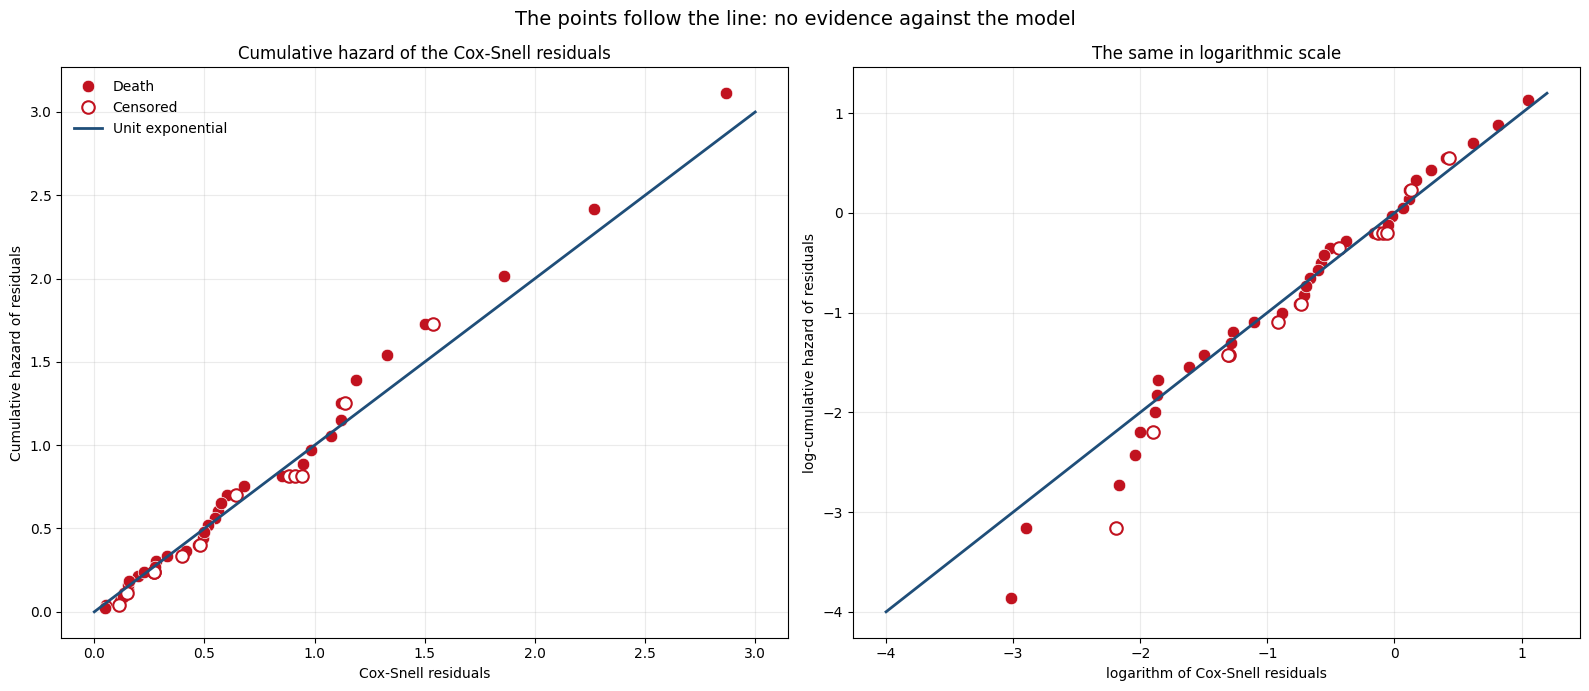

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

PlotPoints(axes[0], rC_KM['cox_snell'], rC_KM['cumulative_hazard'], rC_KM['status'])
axes[0].plot([0, 3], [0, 3], color=line_color, lw=2, label='Unit exponential')
axes[0].set_xlabel("Cox-Snell residuals")
axes[0].set_ylabel("Cumulative hazard of residuals")
axes[0].set_title("Cumulative hazard of the Cox-Snell residuals")

PlotPoints(axes[1], np.log(rC_KM['cox_snell']), np.log(rC_KM['cumulative_hazard']), rC_KM['status'])
axes[1].plot([-4, 1.2], [-4, 1.2], color=line_color, lw=2, label='Unit exponential')
axes[1].set_xlabel("logarithm of Cox-Snell residuals")
axes[1].set_ylabel("log-cumulative hazard of residuals")
axes[1].set_title("The same in logarithmic scale")

for ax in axes:
    ax.grid(True, alpha=0.25)
axes[0].legend(loc='upper left', frameon=False)
fig.suptitle('The points follow the line: no evidence against the model', fontsize=14)
plt.tight_layout()

## Martingale and deviance residuals

The martingale residuals are the difference between the observed number of events of an individual (0 or 1) and the number expected by the model. They are at most 1 and very asymmetric. The deviance residuals,

$$
r_{D_i}=\text{sgn}(r_{M_i})\left[-2\{r_{M_i}+\delta_i\log(\delta_i-r_{M_i})\}\right]^{1/2},
$$

are a transformation of them that is more symmetric around zero. A large positive residual is an individual who died sooner than expected; a large negative one, an individual who lived longer than expected.

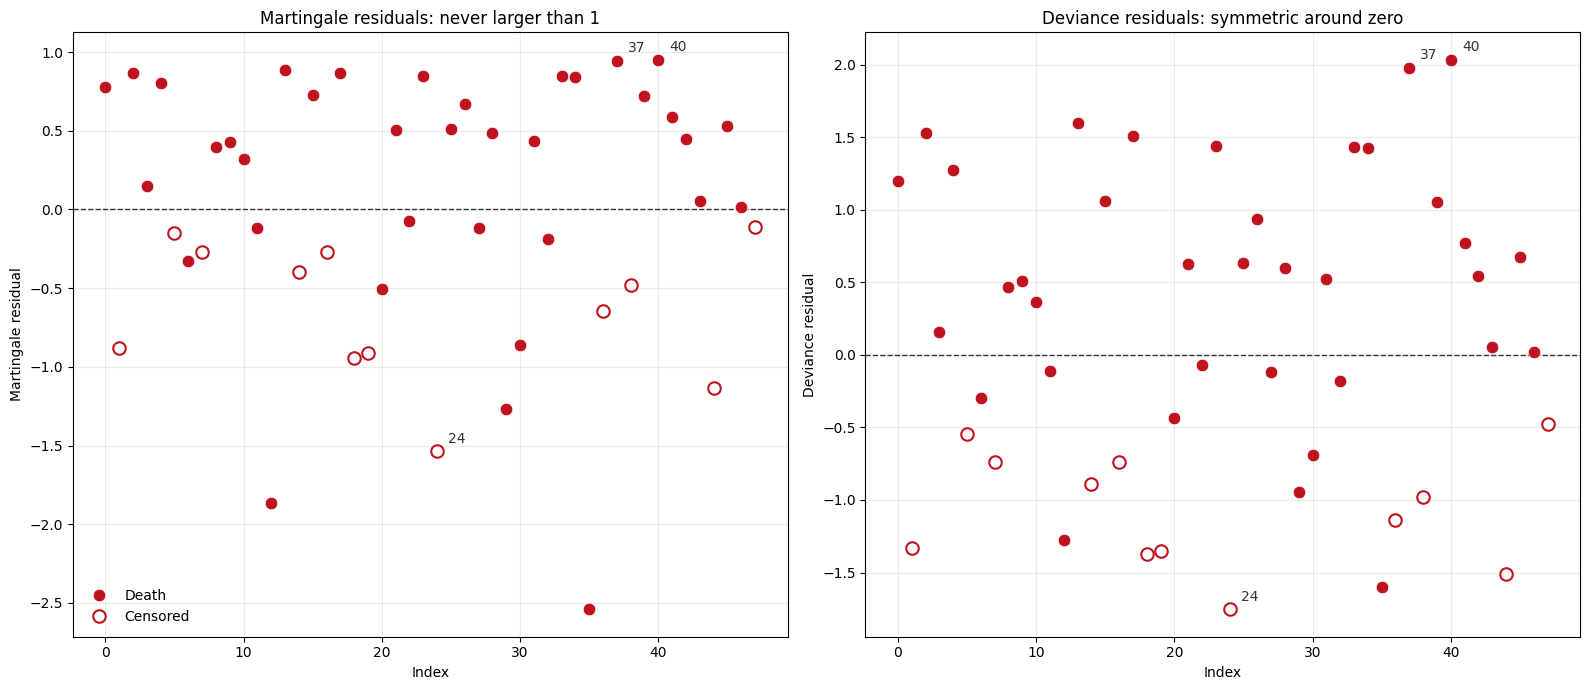

In [13]:
Largest = np.argsort(-np.abs(rD['deviance'].to_numpy()))[:3]   # the three largest deviance residuals

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, residuals, name in zip(axes, [rM['martingale'], rD['deviance']], ['Martingale', 'Deviance']):
    ax.axhline(0, color=ref_color, lw=1, ls='--')
    PlotPoints(ax, residuals.index, residuals, rM['status'])
    LabelPoints(ax, residuals.index, residuals, residuals.index, Largest)
    ax.set_xlabel("Index")
    ax.set_ylabel(f"{name} residual")
    ax.grid(True, alpha=0.25)
axes[0].set_title("Martingale residuals: never larger than 1")
axes[1].set_title("Deviance residuals: symmetric around zero")
axes[0].legend(loc='lower left', frameon=False)
plt.tight_layout()

Against the risk score $\hat\beta^Tx_i$ we see which kind of individual is badly fitted.

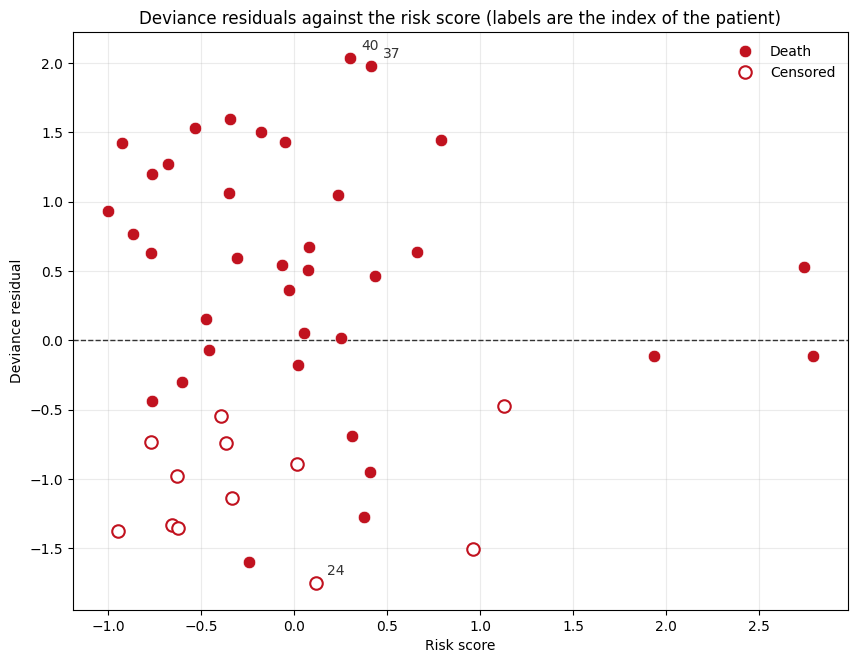

In [14]:
# The residuals come sorted by time; the risk scores are put in the same order
RiskScore = Model.predict_log_partial_hazard(DatOriginal).loc[rD.index]

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.axhline(0, color=ref_color, lw=1, ls='--')
PlotPoints(ax, RiskScore, rD['deviance'], rD['status'])
LabelPoints(ax, RiskScore, rD['deviance'], rD.index, Largest)

ax.set_xlabel("Risk score")
ax.set_ylabel("Deviance residual")
ax.set_title("Deviance residuals against the risk score (labels are the index of the patient)")
ax.legend(loc='best', frameon=False)
ax.grid(True, alpha=0.25)

In [15]:
# The patients with the largest deviance residuals
DatOriginal.assign(risk_score=RiskScore, deviance=rD['deviance']).loc[rD.index[Largest]].round(3)

,time,status,age,sex,bun,ca,hb,pcells,protein,risk_score,deviance
40,1,1,75,1,56,12,11.3,18,0,0.301,2.033
37,1,1,57,1,20,9,5.1,100,1,0.416,1.978
24,40,0,72,1,57,9,12.8,28,1,0.119,-1.753


The two largest positive residuals are patients who died in the first month. The largest negative one is a patient who was still alive after 40 months in spite of a very high bun.

## Check proportional hazard assumption

There is one Schoenfeld residual for each event and each variable: the value of the variable for the individual who had the event, minus its weighted average among the individuals at risk at that time. Once scaled, $\hat\beta_j$ plus the residual estimates the coefficient $\beta_j(t)$ at that time. Under proportional hazards the coefficient does not change with time, so the points must show no trend.

In [16]:
Model.check_assumptions(DatOriginal)

Proportional hazard assumption looks okay.


[]

In [17]:
TestPH = proportional_hazard_test(Model, DatOriginal, time_transform='rank')
TestPH.summary

,test_statistic,p,-log2(p)
bun,0.708375,0.399984,1.321987
hb,0.022869,0.879799,0.184755


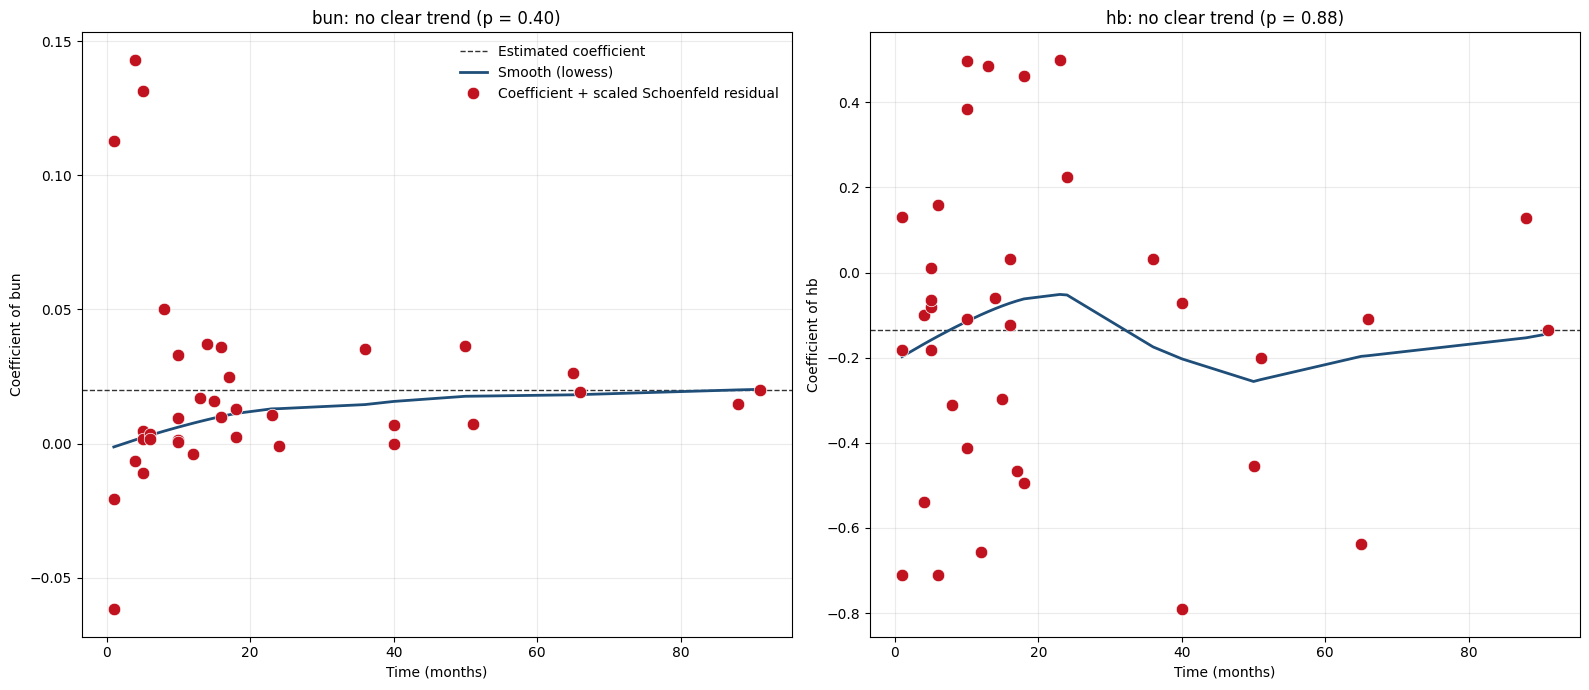

In [18]:
EventTimes = DatOriginal.loc[rSS.index, 'time']

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, variable in zip(axes, rSS.columns):
    beta_t = Model.params_[variable] + rSS[variable]
    smooth = lowess(beta_t, EventTimes, frac=0.9)

    ax.axhline(Model.params_[variable], color=ref_color, lw=1, ls='--', label='Estimated coefficient')
    ax.plot(smooth[:, 0], smooth[:, 1], color=line_color, lw=2, label='Smooth (lowess)')
    ax.plot(EventTimes, beta_t, 'o', color=point_color, markersize=9, markeredgecolor='white', markeredgewidth=0.5,
            label='Coefficient + scaled Schoenfeld residual')
    ax.set_xlabel("Time (months)")
    ax.set_ylabel(f"Coefficient of {variable}")
    ax.set_title(f"{variable}: no clear trend (p = {TestPH.summary.loc[variable, 'p']:.2f})")
    ax.grid(True, alpha=0.25)
axes[0].legend(loc='best', frameon=False)
plt.tight_layout()

## Proportional hazards for hb: log-cumulative hazard plot

We investigate if the assumption of proportional hazards is valid for the variable hb

If the hazards of two groups are proportional, their cumulative hazards are too, $H_1(t)=\psi H_2(t)$, and then $\log H_1(t)=\log\psi+\log H_2(t)$: the logarithms of the cumulative hazards are parallel curves. We divide the patients in four groups with the quartiles of hb and plot the logarithm of the estimated cumulative hazard of each group against the logarithm of time.

In [19]:
DatOriginal["hb_quartiles"] = pd.qcut(DatOriginal["hb"], 4)

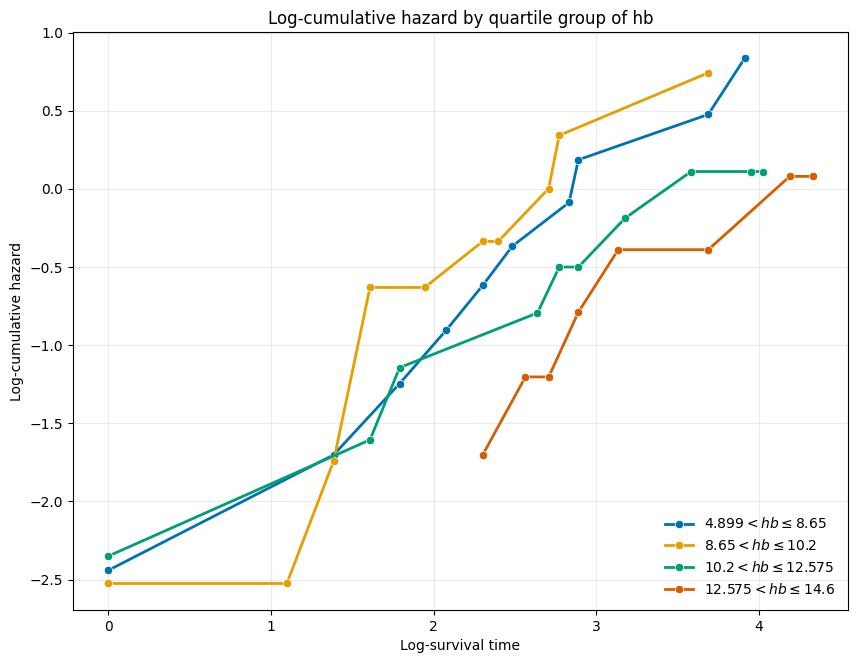

In [20]:
fig, ax = plt.subplots(figsize=(10, 7.5))
for q, color in zip(DatOriginal["hb_quartiles"].cat.categories, ['#0072B2', '#E69F00', '#009E73', '#D55E00']):
    group = (DatOriginal["hb_quartiles"] == q)

    kmf = KaplanMeierFitter()
    kmf.fit(DatOriginal[group]['time'], DatOriginal[group]['status'])

    _ = (-np.log(kmf.survival_function_['KM_estimate'])).reset_index().drop_duplicates()
    # The logarithm needs a positive and finite cumulative hazard
    _ = _[(_['KM_estimate'] > 0) & np.isfinite(_['KM_estimate'])]

    ax.plot(
        np.log(_['timeline']),
        np.log(_['KM_estimate']),
        '-o', color=color, lw=2, markersize=6, markeredgecolor='white', markeredgewidth=0.5,
        label=r"{}$<hb\leq${}".format(q.left, q.right)
    )

ax.set_xlabel("Log-survival time")
ax.set_ylabel("Log-cumulative hazard")
ax.set_title("Log-cumulative hazard by quartile group of hb")
ax.legend(loc='lower right', frameon=False)
ax.grid(True, alpha=0.25)

The curves of the two groups with the lowest hb are above the other two, and after the first months, where there are very few deaths, the curves neither cross systematically nor separate more and more. There is no clear evidence against proportional hazards.